# AT2 — Redes Neurais MLP e Deploy de API

Este notebook treina e avalia um classificador de cancelamento de clientes usando a base Telco Customer Churn.

## 3.1 Contexto e dicionário de dados

A base pública [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) reúne clientes de telecomunicações. O objetivo é estimar a coluna-alvo `Churn` (`Yes` ou `No`) para apoiar ações de retenção. `customerID` foi removida por ser identificador.

| Coluna | Tipo | Significado |
|---|---|---|
| tenure | numérico | Meses como cliente |
| MonthlyCharges | numérico | Cobrança mensal |
| TotalCharges | numérico | Total cobrado |
| Contract | categórico | Tipo de contrato |
| InternetService | categórico | Serviço de internet |
| OnlineSecurity | categórico | Serviço de segurança |
| TechSupport | categórico | Suporte técnico |
| PaymentMethod | categórico | Método de pagamento |
| Churn | alvo categórico | Cancelou o serviço |

In [6]:
from pathlib import Path
import sys
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'dataset.csv').exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / 'data' / 'dataset.csv')
FEATURES = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod']
NUMERICAS = ['tenure', 'MonthlyCharges', 'TotalCharges']
CATEGORICAS = [c for c in FEATURES if c not in NUMERICAS]

## 3.2 Análise exploratória

São verificadas dimensões, tipos, nulos, duplicidades e a distribuição do alvo. `TotalCharges` vem como texto por conter valores vazios e é convertido para numérico; valores inválidos tornam-se ausentes e são imputados apenas dentro do pipeline de treino.

Dimensões: (7043, 21)


,tipo
tenure,int64
MonthlyCharges,float64
TotalCharges,object
Contract,object
InternetService,object
OnlineSecurity,object
TechSupport,object
PaymentMethod,object
Churn,object


,nulos
tenure,0
MonthlyCharges,0
TotalCharges,0
Contract,0
InternetService,0
OnlineSecurity,0
TechSupport,0
PaymentMethod,0
Churn,0


Linhas duplicadas: 0


,quantidade
Churn,
No,5174
Yes,1869


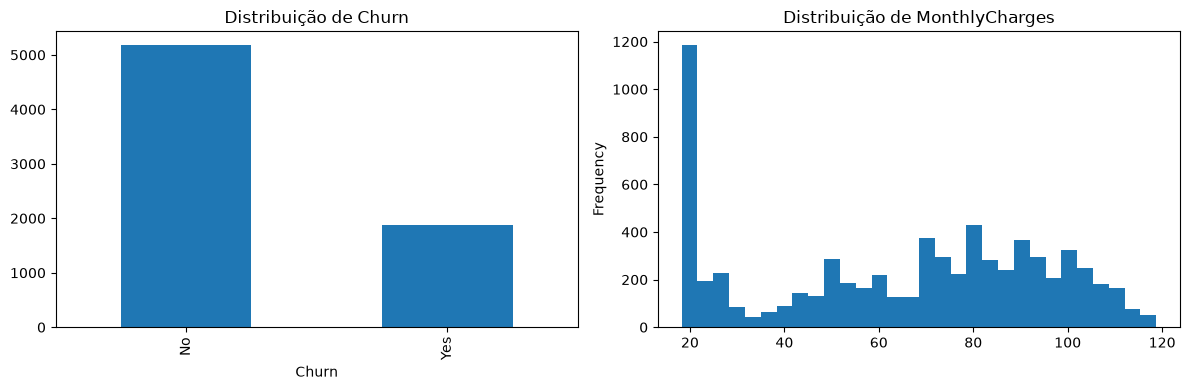

In [7]:
print('Dimensões:', df.shape)
display(df[FEATURES + ['Churn']].dtypes.to_frame('tipo'))
display(df[FEATURES + ['Churn']].isna().sum().to_frame('nulos'))
print('Linhas duplicadas:', df.duplicated().sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
display(df['Churn'].value_counts().rename_axis('Churn').to_frame('quantidade'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Churn'].value_counts().plot(kind='bar', ax=axes[0], title='Distribuição de Churn')
df['MonthlyCharges'].plot(kind='hist', bins=30, ax=axes[1], title='Distribuição de MonthlyCharges')
plt.tight_layout()

## 3.3 Pipeline de Machine Learning

A divisão usa 20% para teste, `random_state=42` e estratificação. Imputação, escala e codificação são ajustadas exclusivamente no treino. A MLP tem duas camadas ocultas `(64, 32)`, taxa de aprendizado explícita e `early_stopping` para limitar treinamento desnecessário.

In [8]:
X = df[FEATURES].copy()
y = df['Churn'].copy()
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
preprocessador = ColumnTransformer([
    ('numericas', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUMERICAS),
    ('categoricas', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CATEGORICAS),
])
pipeline = Pipeline([
    ('preprocessador', preprocessador),
    ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), learning_rate_init=0.001, max_iter=500, early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=42)),
])
pipeline.fit(X_treino, y_treino)
print('Iterações executadas:', pipeline.named_steps['mlp'].n_iter_)

Iterações executadas: 90


## 3.4 Avaliação

As métricas abaixo são calculadas somente no conjunto de teste. Um falso positivo indica que a empresa ofereceria retenção a alguém que não cancelaria; um falso negativo indica um cliente que pode cancelar sem ser identificado. Os resultados dependem da versão da base e dos hiperparâmetros.

Acurácia: 0.7999
              precision    recall  f1-score   support

          No     0.8271    0.9198    0.8710      1035
         Yes     0.6783    0.4679    0.5538       374

    accuracy                         0.7999      1409
   macro avg     0.7527    0.6939    0.7124      1409
weighted avg     0.7876    0.7999    0.7868      1409



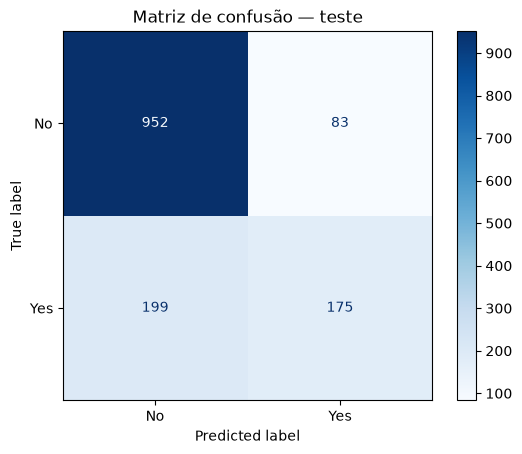

In [9]:
predicoes = pipeline.predict(X_teste)
acuracia = accuracy_score(y_teste, predicoes)
print(f'Acurácia: {acuracia:.4f}')
print(classification_report(y_teste, predicoes, digits=4))
matriz = confusion_matrix(y_teste, predicoes, labels=['No', 'Yes'])
ConfusionMatrixDisplay(matriz, display_labels=['No', 'Yes']).plot(cmap='Blues')
plt.title('Matriz de confusão — teste')
plt.show()

## 3.5 Exportação

O objeto salvo contém tanto o pré-processamento quanto a MLP. Assim, a API recebe os dados brutos e aplica exatamente as mesmas transformações do treinamento.

In [10]:
caminho_modelo = ROOT / 'models' / 'modelo_mlp.joblib'
caminho_modelo.parent.mkdir(exist_ok=True)
joblib.dump(pipeline, caminho_modelo)
modelo_carregado = joblib.load(caminho_modelo)
assert modelo_carregado.predict(X_teste.head(1))[0] in ['No', 'Yes']
print(f'Modelo salvo e recarregado com sucesso: {caminho_modelo}')

Modelo salvo e recarregado com sucesso: C:\atv2-am\models\modelo_mlp.joblib
